<h1> DISPARITY AND DEPTH MAPS</h1>

<div style="display: flex; align-items: center;">
    <img src="https://img.freepik.com/premium-vector/warning-signs-high-voltage-hazard-isolated-white-background_68708-427.jpg?w=2000" alt="Image Alt Text" width="50" height="50" style="margin-right: 20px;">
    <div style="font-size: 15px;margin-right: 30px">
            Each lab must be completed before the beginning of the other lab session.
        <br>
          <strong>Don't forget to entitle your .ipynb file with your name and surname. <strong>
        <br>
         The final submission of the first module has to be done <strong> by Tuesday 20<sup> th</sup>October before 10 am.</strong>
    </div>
</div>

<table>
      <td style="border-left: 3px solid rgba(114, 147, 203, 0.9); background-color: rgba(114, 147, 203, 0.1); font-size: 15px; color: blakc; padding-left: 30px;">
        Don't forget to legend your figures and graphs. Interpretations are expected and must by short but comprehensive.  
      </td>
</table>

#### Contact : anna-louise.brun@u-bordeaux.fr

<img src="https://docs.opencv.org/3.4/stereo_depth.jpg" width="300" height="300">


There will be two parts to this lab.

1. **Disparity Maps**: Generate the map using stereo (Left & Right) images and OpenCV algorithms
2. **Depth Maps**: Using a Neural Network


The main goals of this lab is to be able to understand how to read library and Git documentation and use pre-existing code for your own images. For the OpenCV functions you are expected to try different parameters to understand how they work and how the choice of stereo images affects the final output.

For the Neural Network we provide two options. But you are welcome to try out anything else you may find and compare the results with one of the given networks.

<H2> OPENCV : Disparity map </h2>

First, we need to import opencv, numpy and matplotlib libraries ...

In [ ]:

import time

import cv2
import numpy as np
import matplotlib.pyplot as plt

Then, we need to have a left and a right image. You have three choices :
- use the provided images
- take a picture placing your phone on your left eye, then another (without moving) on your right eye
- take a stereo image from the internet (using google images). As they are provided as a single SBS image, you will have to cut it into two images.

Import the images using cv2.imread() . Display both using matplotlib.

left image shape : (1080, 1920, 3)
right image shape: (1080, 1920, 3)


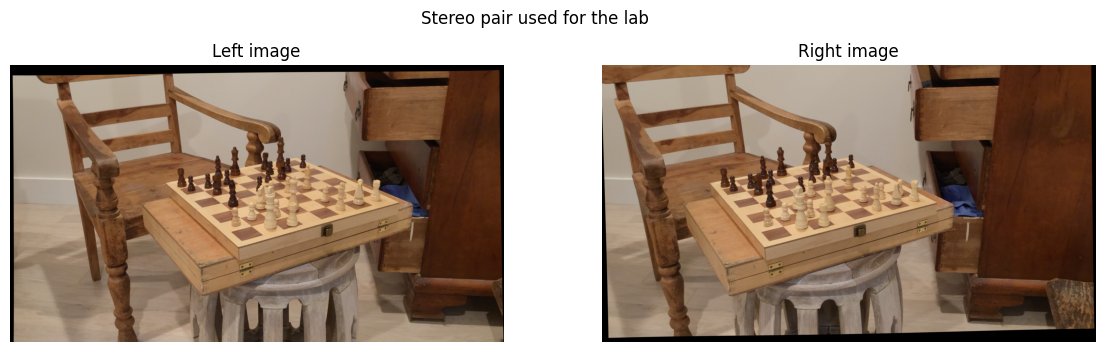

In [ ]:

import os


def load_image(name):
    """Read an image with opencv. cv2.imread does not raise an error when the file is missing (it returns None),
    so we check it ourselves to get a clear message instead of a confusing error later in cvtColor."""
    img = cv2.imread(name)
    if img is None:
        raise FileNotFoundError(
            f"Could not read '{name}'. Current folder: {os.getcwd()} | files here: {sorted(os.listdir('.'))[:20]}\n"
            "Put left.png and right.png in this folder (in colab: upload them with the Files panel on the left) "
            "and run the cell again."
        )
    return img


# opencv loads images as BGR, so we convert to RGB to display them correctly with matplotlib
img_left = load_image('left.png')
img_right = load_image('right.png')

img_left_rgb = cv2.cvtColor(img_left, cv2.COLOR_BGR2RGB)
img_right_rgb = cv2.cvtColor(img_right, cv2.COLOR_BGR2RGB)

print("left image shape :", img_left.shape)
print("right image shape:", img_right.shape)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].imshow(img_left_rgb)
axes[0].set_title("Left image")
axes[1].imshow(img_right_rgb)
axes[1].set_title("Right image")
for ax in axes:
    ax.axis('off')
plt.suptitle("Stereo pair used for the lab")
plt.show()

Now, we can compute a disparity map using StereoBM or StereoSGBM algorithms. You can choose which one you prefer.
- for StereoBM refer to : https://docs.opencv.org/3.4/dd/d53/tutorial_py_depthmap.html
- for StereoSGBM : https://www.programcreek.com/python/example/110664/cv2.StereoSGBM_create

In both case, you will have to play with the parameters to obtain a decent (i.e. smooth) disparity map.

SGBM computed in 0.26 s


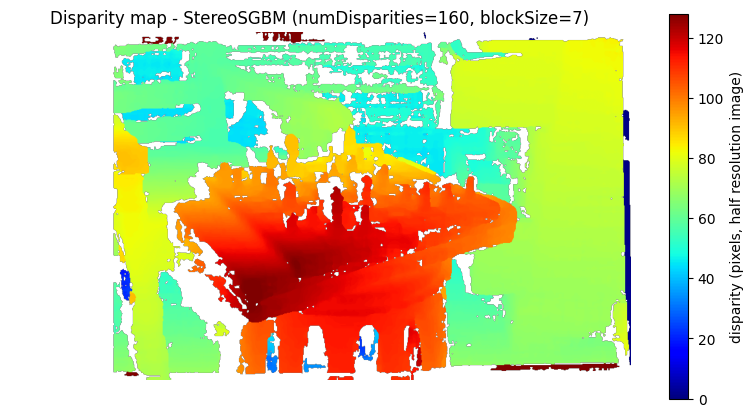

In [ ]:

# StereoSGBM works on single channel images, so we use grayscale.
# We also halve the resolution: the disparities become smaller (so we need a smaller search range)
# and the computation is faster.
gray_left = cv2.cvtColor(img_left, cv2.COLOR_BGR2GRAY)
gray_right = cv2.cvtColor(img_right, cv2.COLOR_BGR2GRAY)

scale = 0.5
gray_left_s = cv2.resize(gray_left, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
gray_right_s = cv2.resize(gray_right, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)


def compute_sgbm(left, right, num_disp=160, block_size=7, p2_factor=32, uniqueness=10, speckle_window=100):
    """Return the disparity map (in pixels) computed with StereoSGBM. Invalid pixels are <= 0."""
    # P1 and P2 are the smoothness penalties, the OpenCV doc advises 8*cn*bs^2 and 32*cn*bs^2 (cn = 1 for grayscale)
    stereo = cv2.StereoSGBM_create(
        minDisparity=0,
        numDisparities=num_disp,          # must be divisible by 16
        blockSize=block_size,
        P1=8 * block_size ** 2,
        P2=p2_factor * block_size ** 2,
        disp12MaxDiff=1,                  # left-right consistency check
        uniquenessRatio=uniqueness,
        speckleWindowSize=speckle_window,
        speckleRange=2,
        mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY,
    )
    # OpenCV returns fixed point values (disparity * 16)
    return stereo.compute(left, right).astype(np.float32) / 16.0


t0 = time.time()
disparity = compute_sgbm(gray_left_s, gray_right_s)
print(f"SGBM computed in {time.time() - t0:.2f} s")

# pixels without a valid match are masked so they appear in white instead of polluting the colormap
disp_masked = np.ma.masked_less_equal(disparity, 0)

plt.figure(figsize=(10, 5))
plt.imshow(disp_masked, cmap='jet', vmin=0, vmax=128)
plt.colorbar(label="disparity (pixels, half resolution image)")
plt.title("Disparity map - StereoSGBM (numDisparities=160, blockSize=7)")
plt.axis('off')
plt.show()

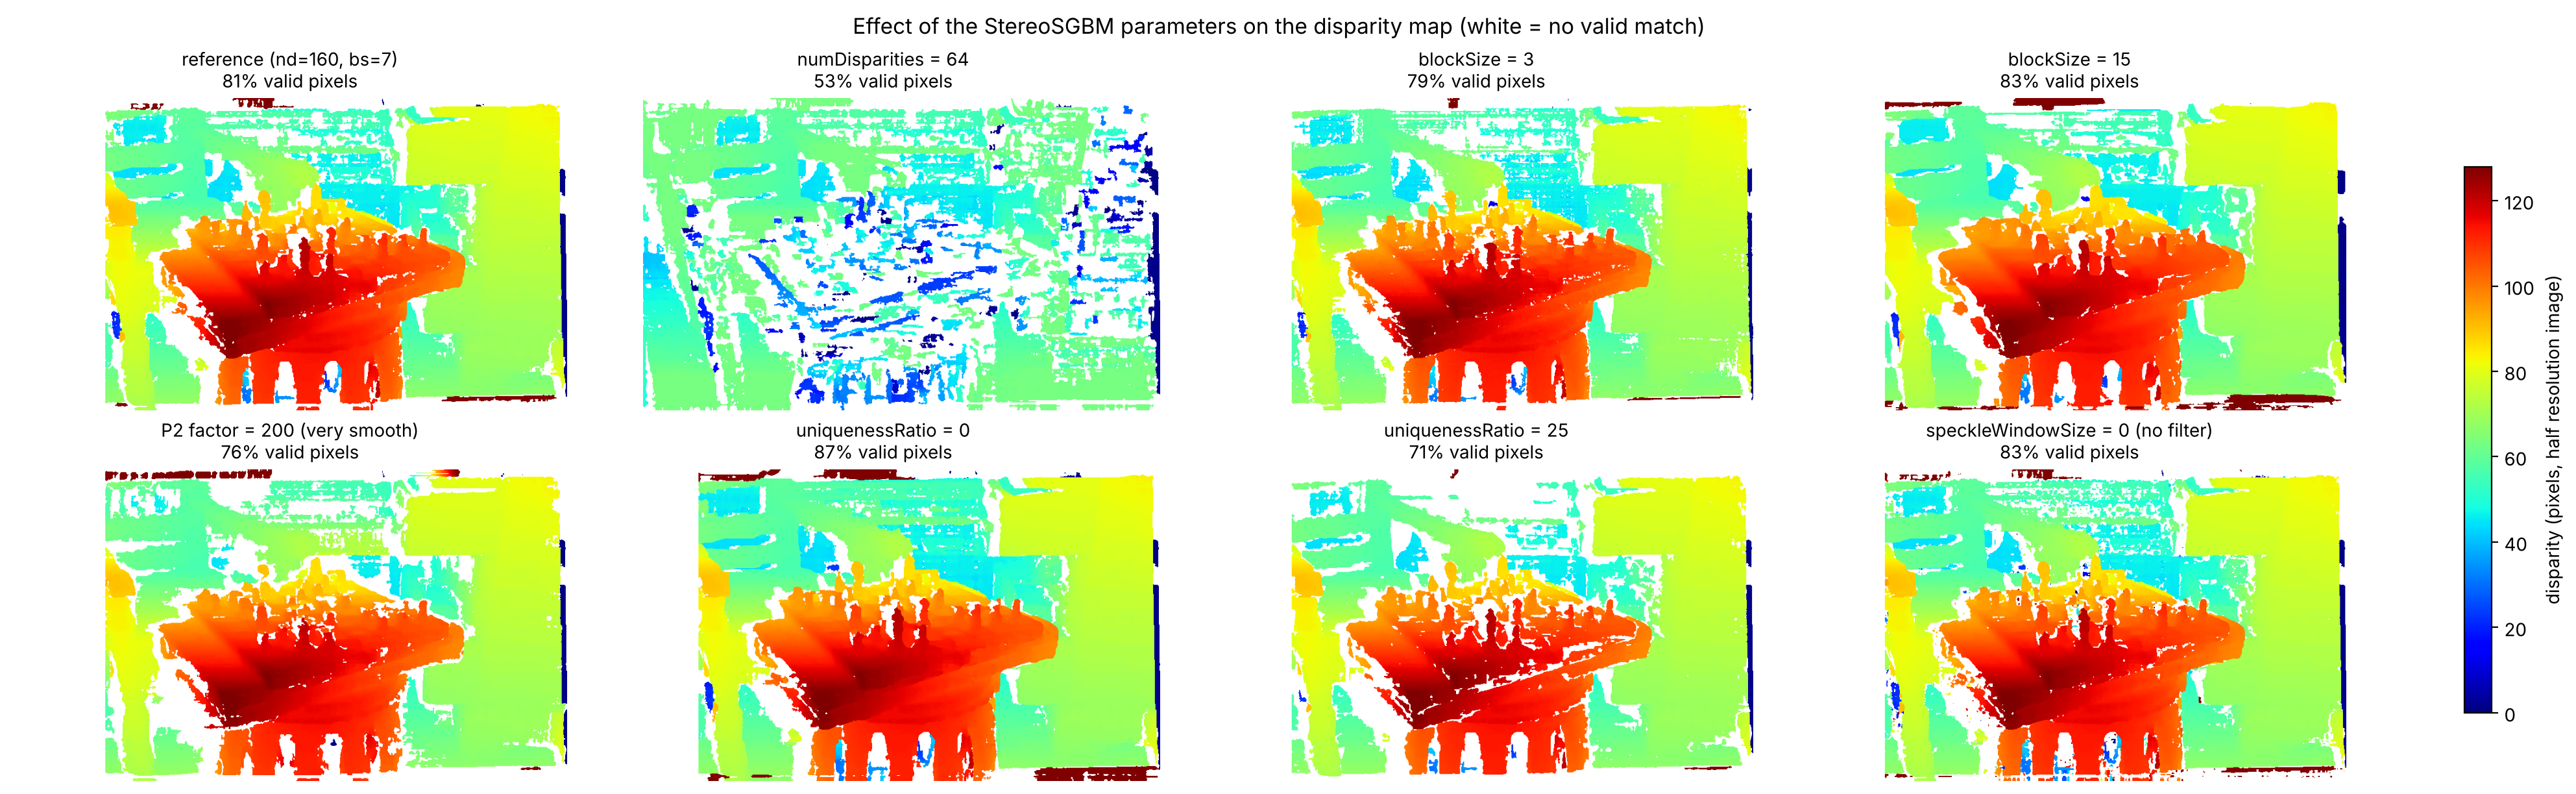

In [ ]:

# Parameter study: we change one parameter at a time (compared to the reference settings above)
settings = [
    ("reference (nd=160, bs=7)", {}),
    ("numDisparities = 64", dict(num_disp=64)),
    ("blockSize = 3", dict(block_size=3)),
    ("blockSize = 15", dict(block_size=15)),
    ("P2 factor = 200 (very smooth)", dict(p2_factor=200)),
    ("uniquenessRatio = 0", dict(uniqueness=0)),
    ("uniquenessRatio = 25", dict(uniqueness=25)),
    ("speckleWindowSize = 0 (no filter)", dict(speckle_window=0)),
]

fig, axes = plt.subplots(2, 4, figsize=(20, 6), constrained_layout=True)
for ax, (title, params) in zip(axes.ravel(), settings):
    d = compute_sgbm(gray_left_s, gray_right_s, **params)
    valid = (d[:, 160:] > 0).mean() * 100   # ignore the left band where no match is possible
    im = ax.imshow(np.ma.masked_less_equal(d, 0), cmap='jet', vmin=0, vmax=128)
    ax.set_title(f"{title}\n{valid:.0f}% valid pixels", fontsize=10)
    ax.axis('off')
fig.suptitle("Effect of the StereoSGBM parameters on the disparity map (white = no valid match)")
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.8, label="disparity (pixels, half resolution image)")
plt.show()

Question: Comment on what parameters were the most important to be tuned and the quality of the output (visual quality) that you observe.



#answer

**Most important parameters**

- **`numDisparities`** was clearly the most important one. The shift between the two views is large: the closest objects (the chess board and the stool) move by about 110-120 pixels on the half resolution images. With `numDisparities=64` the search range is too short, only 53% of the pixels get a value and the map is mostly meaningless. With 160 it works, and larger values (192, 256) give practically the same map but take longer. The white band on the left of the maps is expected: the first `numDisparities` columns cannot be computed because the matching window would fall outside the right image.
- **`blockSize`**: a small window keeps more detail and a large one gives a smoother and denser map (79%, 81% and 83% of valid pixels for 3, 7 and 15). On this pair the visual difference was small, so I kept 7 as a compromise.
- **`P2`** (smoothness penalty): a larger value gives a smoother map but fewer valid pixels (76% with a factor of 200 against 81% with 32).
- **`uniquenessRatio`** and the speckle filter: a higher uniqueness ratio rejects the ambiguous matches, so there are more holes (71% of valid pixels with 25, 87% with 0, but the extra pixels are the less reliable ones). The speckle filter removes small isolated blobs (83% without it, 81% with it).

**Quality of the output**

The order of the depths is correct and the map is smooth on the large surfaces. Reading the colorbar, the board and the stool are the closest (disparity around 115), the front chair leg and the dresser are in the middle (around 73), and the wall is the farthest (around 49). The main defects are:

- white holes (no valid match) around the chess pieces and behind the chair, because these points are visible in only one of the two images (occlusions), and also on the plain wall and the floor, which have almost no texture;
- wrong values along the black borders of the images (dark red and dark blue strips), where there is nothing to match;
- streak-like artifacts on the board, which are typical of semi-global matching, and the thin chess pieces are only roughly outlined.

**Effect of the stereo pair.** The two images appear to be already rectified (the same point is on almost the same row in both images), which is why a search along the rows works well. The result depends on the scene: textured areas such as the board are reliable, while plain areas and parts seen by only one camera give holes.

Some other references

- General unformal : https://lookingglassfactory.com/blog/depth-map
- Block matching : https://en.wikipedia.org/wiki/Block-matching_algorithm
- Stereo BM: three-step search algo : https://www.digitalxplore.org/up_proc/pdf/62-1397565973101-104.pdf and https://www.sciencedirect.com/science/article/pii/S1877050915007346
- Stereo SGBM: Semi-Global Matching : https://citeseerx.ist.psu.edu/viewdoc/download?doi=10.1.1.88.8897&rep=rep1&type=pdf

If you are interested then you may check the other algorithm you did choose and see the initial results to comment on how the time and the final output differ from the one you chose

StereoBM  : 38 ms per image, 52% valid pixels
StereoSGBM: 106 ms per image, 81% valid pixels


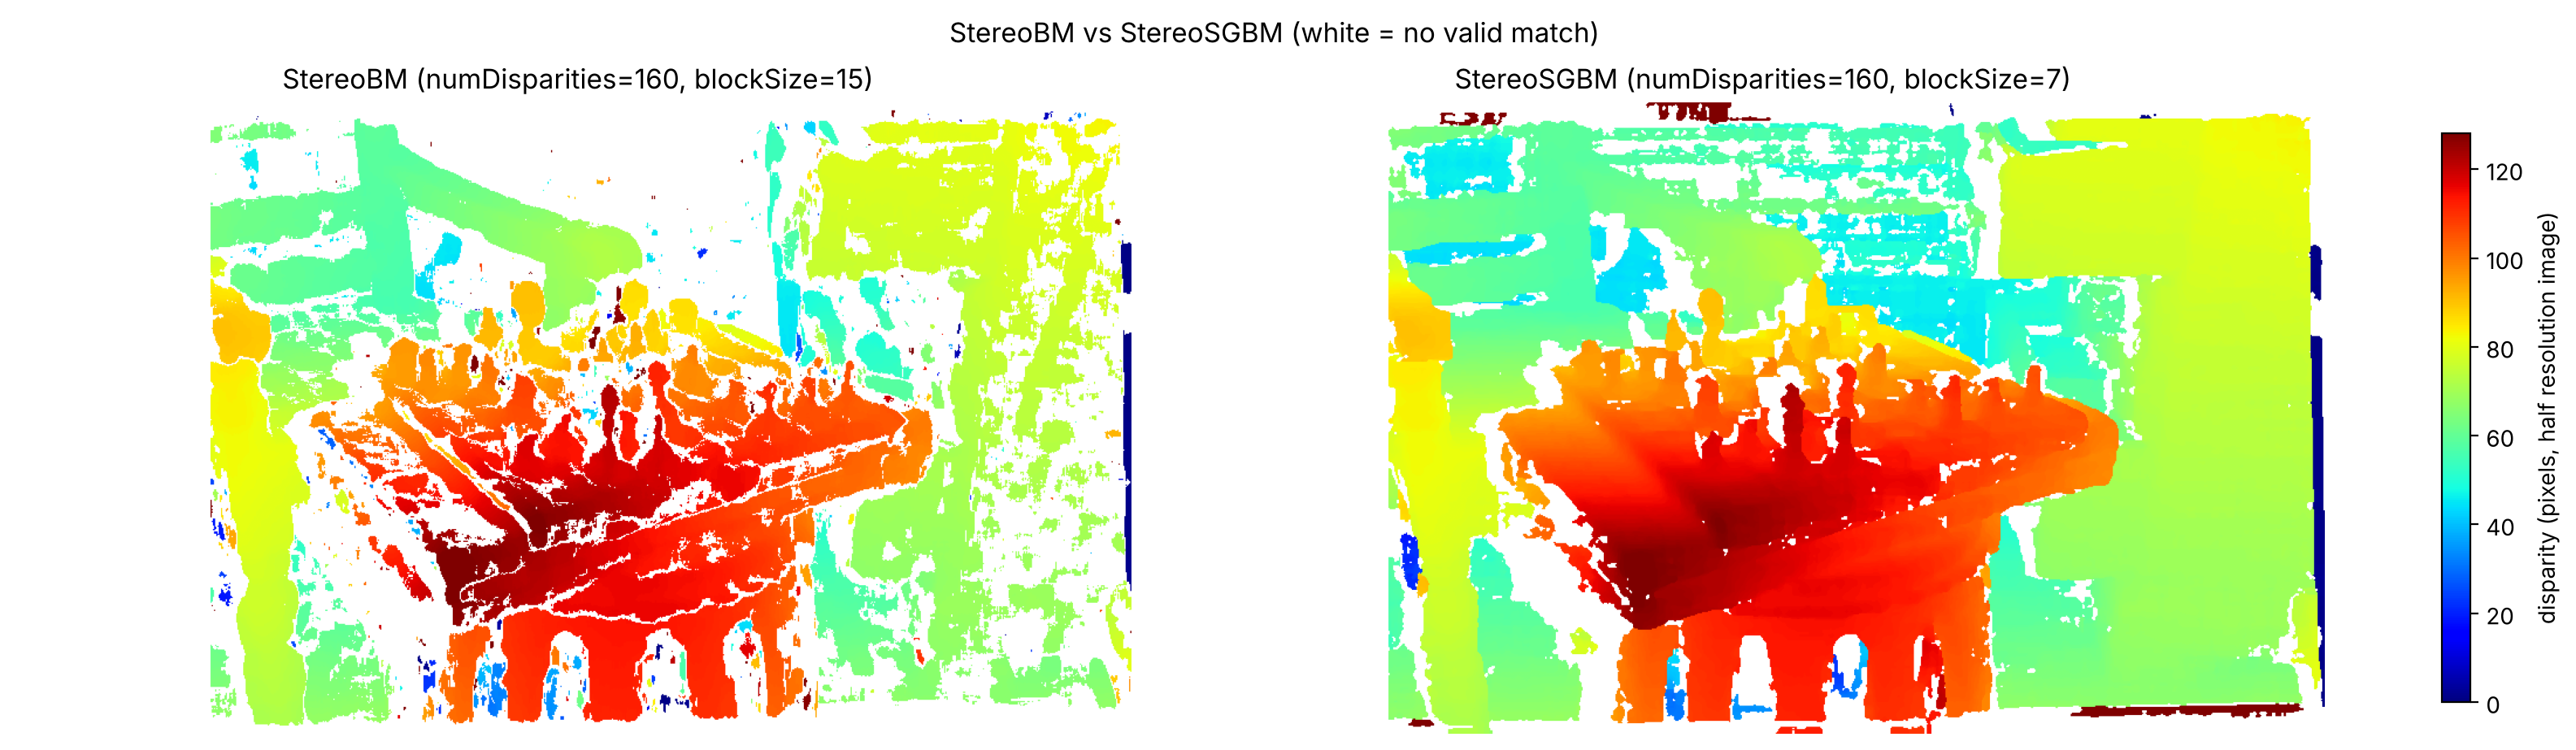

In [ ]:

# Bonus q the other algorithm (StereoBM) with the same images, to compare quality and computation time
bm = cv2.StereoBM_create(numDisparities=160, blockSize=15)

n_runs = 10
t0 = time.time()
for _ in range(n_runs):
    disp_bm = bm.compute(gray_left_s, gray_right_s).astype(np.float32) / 16.0
time_bm = (time.time() - t0) / n_runs

t0 = time.time()
for _ in range(n_runs):
    disp_sgbm = compute_sgbm(gray_left_s, gray_right_s)
time_sgbm = (time.time() - t0) / n_runs

print(f"StereoBM  : {time_bm * 1000:.0f} ms per image, {(disp_bm[:, 160:] > 0).mean() * 100:.0f}% valid pixels")
print(f"StereoSGBM: {time_sgbm * 1000:.0f} ms per image, {(disp_sgbm[:, 160:] > 0).mean() * 100:.0f}% valid pixels")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), constrained_layout=True)
im = axes[0].imshow(np.ma.masked_less_equal(disp_bm, 0), cmap='jet', vmin=0, vmax=128)
axes[0].set_title("StereoBM (numDisparities=160, blockSize=15)")
im = axes[1].imshow(np.ma.masked_less_equal(disp_sgbm, 0), cmap='jet', vmin=0, vmax=128)
axes[1].set_title("StereoSGBM (numDisparities=160, blockSize=7)")
for ax in axes:
    ax.axis('off')
fig.suptitle("StereoBM vs StereoSGBM (white = no valid match)")
fig.colorbar(im, ax=axes, shrink=0.9, label="disparity (pixels, half resolution image)")
plt.show()

#answer

I chose StereoSGBM for the main part and tried StereoBM afterwards, with the same `numDisparities` and a `blockSize` of 15 (the other parameters were left at their default values, so BM is less finely tuned). StereoBM only does local block matching: it compares a window of the left image with windows of the right image along the same row, without any smoothness constraint. The result is much more fragmented: only about 52% of the pixels have a value, against 81% for SGBM, with large holes on the wall, the floor and the dresser. StereoSGBM adds smoothness penalties (P1, P2) along several paths in the image, which gives a denser and smoother map.

For the computation time, StereoBM is about 3 times faster (see the printed times above), but both are fast on these half resolution images, so here the better quality of SGBM clearly wins. The difference in time would matter more for larger images or a larger disparity range.

<h2> MONOCULAR DEPTH ESTIMATION USING A DNN (Deep Neural Network)<h2>

### For this part you might need to create your own environnement

1. Create the environment folder :
python3 -m venv /path/to/env_name
2. Activate it :
source /path/to/env_name/bin/activate
3. Install packages :
pip install numpy torch ...

There are a lot of DNN for creating a depth map using only one image. I suggest you try :
- MiDaS https://github.com/isl-org/MiDaS
- MonoDepth2 : https://github.com/nianticlabs/monodepth2


You can also choose another DNN if you want.
To use them, simply clone the git repository and use the model (there are different models for different results in MiDaS for example). You don't have to retrain the model. All instructions are in the git.
You only need one image as an input.

MiDaS

Downloading: "https://github.com/intel-isl/MiDaS/zipball/master" to /root/.cache/torch/hub/master.zip


/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


Loading weights:  None
The repository rwightman_gen-efficientnet-pytorch does not belong to the list of trusted repositories and as such cannot be downloaded. Do you trust this repository and wish to add it to the trusted list of repositories (y/N)?y
Downloading: "https://github.com/rwightman/gen-efficientnet-pytorch/zipball/master" to /root/.cache/torch/hub/master.zip


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-weights/tf_efficientnet_lite3-b733e338.pth" to /root/.cache/torch/hub/checkpoints/tf_efficientnet_lite3-b733e338.pth
Downloading: "https://github.com/isl-org/MiDaS/releases/download/v2_1/midas_v21_small_256.pt" to /root/.cache/torch/hub/checkpoints/midas_v21_small_256.pt


100%|██████████| 81.8M/81.8M [00:00<00:00, 108MB/s] 
Using cache found in /root/.cache/torch/hub/intel-isl_MiDaS_master


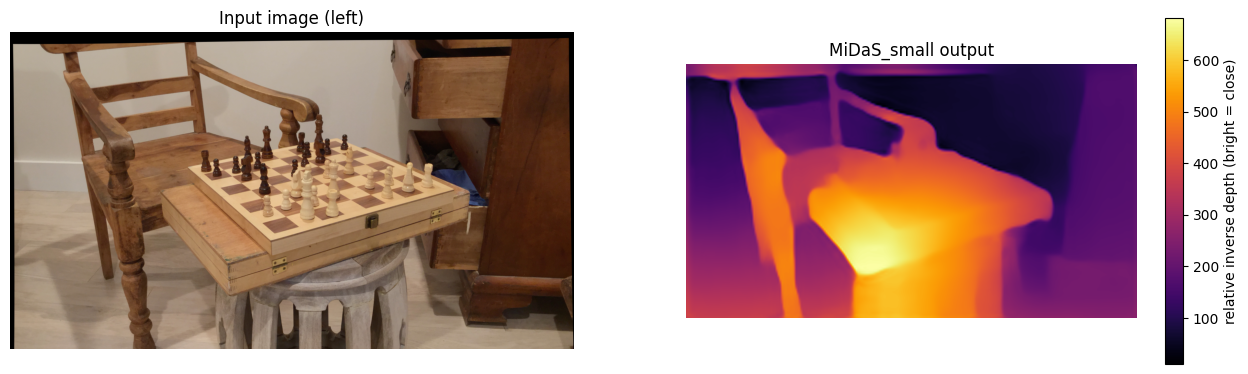

In [ ]:

# requirements: pip install torch torchvision timm opencv-python matplotlib
# We use the MiDaS_small model because it is light and can run on a CPU
# (the other models, DPT_Hybrid and DPT_Large, are more accurate but much heavier).
# Note: if torch asks whether you trust a repository, answer y
import torch

midas = torch.hub.load("intel-isl/MiDaS", "MiDaS_small", trust_repo=True)
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
midas.to(device)
midas.eval()

# transforms that resize and normalise the image the way the model expects
midas_transforms = torch.hub.load("intel-isl/MiDaS", "transforms", trust_repo=True)
transform = midas_transforms.small_transform

# MiDaS only needs ONE image: we use the left one
input_batch = transform(img_left_rgb).to(device)

with torch.no_grad():
    prediction = midas(input_batch)
    # the network output is smaller than the image, we resize it to the original size
    prediction = torch.nn.functional.interpolate(
        prediction.unsqueeze(1),
        size=img_left_rgb.shape[:2],
        mode="bicubic",
        align_corners=False,
    ).squeeze()

depth_midas = prediction.cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].imshow(img_left_rgb)
axes[0].set_title("Input image (left)")
im = axes[1].imshow(depth_midas, cmap='inferno')
axes[1].set_title("MiDaS_small output")
fig.colorbar(im, ax=axes[1], label="relative inverse depth (bright = close)")
for ax in axes:
    ax.axis('off')
plt.show()

MonoDepth2

Cloning into 'monodepth2'...
remote: Enumerating objects: 186, done.
remote: Counting objects: 100% (6/6), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 186 (delta 2), reused 1 (delta 0), pack-reused 180 (from 1)
Receiving objects: 100% (186/186), 10.27 MiB | 13.68 MiB/s, done.
Resolving deltas: 100% (91/91), done.
-> Downloading pretrained model to models/mono+stereo_640x192.zip
   Unzipping model...
   Model unzipped to models/mono+stereo_640x192
-> Loading model from  models/mono+stereo_640x192
   Loading pretrained encoder
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:135: UserWarning: Using 'weights' as positional parameter(s) is deprecated since 0.13 and may be removed in the future. Please use keyword parameter(s) instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the f

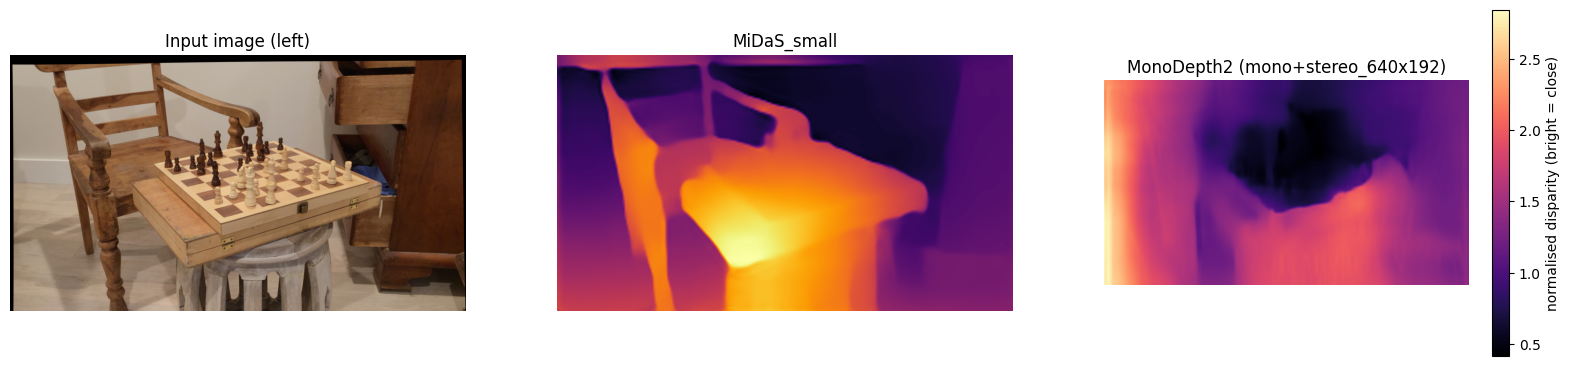

In [ ]:

# 1) get the code (the "!" lines are shell commands, this works in colab or jupyter)
!git clone https://github.com/nianticlabs/monodepth2.git

# 2) test_simple.py saves its results next to the input image, so we put a copy of the image in its own folder
!mkdir -p monodepth2/my_images
!cp left.png monodepth2/my_images/left.png

# 3) run the pretrained model (mono+stereo, 640x192); the weights are downloaded automatically the first time
!cd monodepth2 && python test_simple.py --image_path my_images/left.png --model_name mono+stereo_640x192

# 4) load the predicted disparity (npy file) and display it
disp_mono = np.load('monodepth2/my_images/left_disp.npy')[0, 0]
print("raw output shape:", disp_mono.shape)

# the model works at 640x192, we resize the result to the size of our image to compare it with the others
disp_mono_full = cv2.resize(disp_mono, (img_left.shape[1], img_left.shape[0]))

fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
axes[0].imshow(img_left_rgb)
axes[0].set_title("Input image (left)")
axes[1].imshow(depth_midas, cmap='inferno')
axes[1].set_title("MiDaS_small")
im = axes[2].imshow(disp_mono_full, cmap='magma')
axes[2].set_title("MonoDepth2 (mono+stereo_640x192)")
fig.colorbar(im, ax=axes[2], label="normalised disparity (bright = close)")
for ax in axes:
    ax.axis('off')
plt.show()

Comment on the outputs that you get with the two models.



**MiDaS (MiDaS_small).** The output is a dense and very smooth map, without any hole, even on the white wall and the floor where the stereo map has holes. The order of the objects is plausible: the board and the stool are the brightest (closest), then the chair, and the back wall is the darkest. The weak points are that the edges are blurry, and that the small chess pieces are not distinguished from the board, since the model is the small one and works at a low resolution. Another error is that the big dresser on the right is dark, much closer to the value of the wall than to the one of the chair, whereas in the stereo map its disparity is clearly higher than the wall and similar to the chair. Also, the output is a *relative inverse depth*, so the values have no unit and cannot be compared directly with the disparity in pixels from OpenCV; only the order of the objects can be compared.

**MonoDepth2.** The output is very blurry and has almost no detail: the chair, the board and the stool are not separated from each other. The darkest (farthest) zone is in the upper middle of the image and covers the wall and the upper part of the board with the chess pieces, so the board, which is the closest object in the stereo map, is not recognised as such. The lower part of the image (floor, stool) is brighter, so the map mostly follows a generic "bottom is near, top is far" pattern instead of the real objects. The dresser also has a low value, and there is a thin bright strip along the left edge that does not correspond to any object (probably an effect of the black border of the image). This is not surprising: the model was trained in a self-supervised way on KITTI driving scenes and works on a 640x192 image, so our indoor close-up scene (squeezed from 16:9 to this size) is far from its training data.

**Comparison.** The stereo map is based on real pixel shifts between two views, so its depth order is reliable where matches are found (it can be converted to metric depth if the baseline and the focal length are known), but it has holes at occlusions and on textureless areas, and it needs two rectified images. The two networks need only one image and give a complete map without holes, but they guess the depth from learned cues, so they can be wrong and depend on their training data. On this image MiDaS gave the most convincing monocular result, MonoDepth2 the weakest, and SGBM the sharpest object borders where it found matches.

References

- https://paperswithcode.com/task/monocular-depth-estimation